# Prototypical Network pour le Few-Shot Learning

Dans cette partie, nous implémentons un **Prototypical Network (ProtoNet)**,
une méthode de Few-Shot Learning appartenant à la famille des méthodes
**metric-based**.

L'objectif du Few-Shot Learning est de permettre à un modèle de reconnaître
de nouvelles classes à partir d'un nombre très limité d'exemples.

Notre expérimentation utilise :

- **Dataset :** Omniglot
- **Backbone :** ResNet18
- **Méthode :** Prototypical Network
- **Configuration :** 5-way
- **Entraînement :** 5-way 1-shot
- **Query :** 5 images par classe
- **Nombre d'épisodes d'entraînement :** 1000
- **Évaluation :** 5-way 1-shot et 5-way 5-shot

Le principe général de ProtoNet est d'apprendre un espace de représentation
dans lequel les exemples appartenant à une même classe sont proches.

Pour chaque classe, un **prototype** est calculé à partir des exemples du
Support Set. Une nouvelle image du Query Set est ensuite classée en fonction
de sa distance aux différents prototypes.

In [60]:
!pip install -q easyfsl


## 2. Importation des bibliothèques

Les principales bibliothèques utilisées sont :

- **PyTorch** : construction et entraînement du réseau de neurones.
- **Torchvision** : chargement du dataset Omniglot et utilisation de ResNet18.
- **EasyFSL** : construction des épisodes Few-Shot.
- **NumPy** : manipulation numérique des résultats.
- **Matplotlib** : visualisation des images et des courbes d'apprentissage.
- **Scikit-learn** : calcul de Precision, Recall et F1-score.

PyTorch constitue le framework principal utilisé pour l'implémentation
du Prototypical Network.

In [2]:
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as tud

import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from easyfsl.samplers import TaskSampler
from easyfsl.datasets import WrapFewShotDataset

In [3]:
_original_sampler_init = tud.Sampler.__init__

def _patched_sampler_init(self, *args, **kwargs):
    pass

tud.Sampler.__init__ = _patched_sampler_init

## 3. Reproductibilité et utilisation du GPU

Une graine aléatoire (`seed = 42`) est fixée afin de rendre les expériences
plus reproductibles.

La reproductibilité est importante dans une expérimentation de Machine
Learning car l'échantillonnage des épisodes et l'initialisation des poids
peuvent influencer les résultats.

Le programme vérifie également la disponibilité d'un GPU.

Si un GPU CUDA est disponible, le modèle et les données sont exécutés
sur celui-ci afin d'accélérer l'entraînement.

In [15]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device :", device)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Device : cuda
GPU : Tesla T4


4. Configuration expérimentale

Nous utilisons le protocole expérimental suivant :

N = 5 classes par épisode ;
K = 1 exemple de support par classe pendant l'entraînement ;
Q = 5 exemples de query par classe ;
1000 épisodes d'entraînement.

Le nombre d'images du Support Set est donc :

$$
N \times K = 5 \times 1 = 5
$$

Le nombre d'images du Query Set est :

$$
N \times Q = 5 \times 5 = 25
$$

Ainsi, chaque épisode d'entraînement contient 5 images de support et 25 images de query.

In [16]:
# Nombre de classes par épisode
N_WAY = 5

# Nombre d'exemples support par classe pendant l'entraînement
K_SHOT_TRAIN = 1

# Nombre de queries par classe
Q_QUERY = 5

# Nombre d'épisodes d'entraînement
N_TRAINING_EPISODES = 1000

# Dimension des embeddings
FEATURE_DIMENSION = 128

# Taille des images
IMAGE_SIZE = 84

# Learning rate
LEARNING_RATE = 1e-4

# Weight decay
WEIGHT_DECAY = 1e-5

# Nombre d'épisodes pour l'évaluation
N_EVAL_EPISODES = 100

print("Configuration")
print("-----------------------------")
print("N-way :", N_WAY)
print("K-shot train :", K_SHOT_TRAIN)
print("Query par classe :", Q_QUERY)
print("Episodes train :", N_TRAINING_EPISODES)
print("Embedding :", FEATURE_DIMENSION)
print("Image size :", IMAGE_SIZE)
print("Learning rate :", LEARNING_RATE)
print("-----------------------------")

Configuration
-----------------------------
N-way : 5
K-shot train : 1
Query par classe : 5
Episodes train : 1000
Embedding : 128
Image size : 84
Learning rate : 0.0001
-----------------------------


5. Prétraitement des images

Avant d'être fournies au réseau, les images sont transformées afin d'avoir un format compatible avec l'architecture utilisée.

Les principales transformations sont :

conversion des images en tenseurs ;
redimensionnement si nécessaire ;
normalisation des valeurs des pixels.

La normalisation permet d'obtenir des données plus adaptées à l'apprentissage du réseau de neurones.

In [17]:
transform = transforms.Compose([
    
    # Omniglot est en niveaux de gris.
    # ResNet18 utilise 3 canaux.
    transforms.Grayscale(num_output_channels=3),
    
    # Redimensionnement
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    
    # Conversion en tenseur
    transforms.ToTensor(),
    
    # Normalisation
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

In [18]:
print("Chargement de Omniglot...")

raw_train_dataset = datasets.Omniglot(
    root="./data",
    background=True,
    download=True,
    transform=transform
)

raw_test_dataset = datasets.Omniglot(
    root="./data",
    background=False,
    download=True,
    transform=transform
)

print("Nombre d'images train :", len(raw_train_dataset))
print("Nombre d'images test :", len(raw_test_dataset))

Chargement de Omniglot...
Nombre d'images train : 19280
Nombre d'images test : 13180


In [19]:
train_dataset = WrapFewShotDataset(
    raw_train_dataset
)

test_dataset = WrapFewShotDataset(
    raw_test_dataset
)

print(
    "Nombre de classes train :",
    len(train_dataset.get_labels())
)

print(
    "Nombre de classes test :",
    len(test_dataset.get_labels())
)

Scrolling dataset's labels...: 100%|██████████| 13180/13180 [00:09<00:00, 1419.98it/s]

Nombre de classes train : 19280
Nombre de classes test : 13180


7. Construction des épisodes Few-Shot

Contrairement à un apprentissage classique où les données sont généralement organisées sous forme de mini-batches fixes, le Few-Shot Learning utilise un apprentissage épisodique.

Chaque épisode constitue une petite tâche de classification.

Un épisode contient deux ensembles :

Support Set

Le Support Set contient les exemples utilisés pour définir les classes de l'épisode.

On le note :

$$
S = {(x_i,y_i)}
$$

Query Set

Le Query Set contient les exemples utilisés pour évaluer la capacité du modèle à reconnaître les classes à partir du Support Set.

On le note :

$$
Q = {(x_j,y_j)}
$$

Dans notre configuration :

$$
N=5,\quad K=1,\quad Q=5
$$

Chaque épisode correspond donc à une tâche de classification 5-way 1-shot avec 5 exemples de query par classe.

In [20]:
def create_episodic_loader(
    dataset,
    n_way,
    n_shot,
    n_query,
    n_tasks,
    num_workers=2
):
    
    sampler = TaskSampler(
        dataset,
        n_way=n_way,
        n_shot=n_shot,
        n_query=n_query,
        n_tasks=n_tasks
    )
    
    loader = DataLoader(
        dataset,
        batch_sampler=sampler,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        collate_fn=sampler.episodic_collate_fn
    )
    
    return loader, sampler

8. Vérification d'un épisode

Avant de commencer l'entraînement, nous vérifions la structure d'un épisode généré par EasyFSL.

Pour chaque épisode, nous obtenons :

support_images : images du Support Set ;
support_labels : labels correspondants ;
query_images : images du Query Set ;
query_labels : labels correspondants ;
class_ids : identifiants réels des classes.

Cette vérification permet de s'assurer que les données sont correctement organisées avant de les transmettre au modèle.

In [24]:
test_loader, test_sampler = create_episodic_loader(
    train_dataset,
    n_way=5,
    n_shot=1,
    n_query=5,
    n_tasks=1
)

episode = next(iter(test_loader))

print("Nombre d'éléments retournés :", len(episode))

support_images, support_labels, query_images, query_labels, class_ids = episode

print("\nSupport images :", support_images.shape)
print("Support labels :", support_labels.shape)

print("\nQuery images :", query_images.shape)
print("Query labels :", query_labels.shape)

print("\nClass IDs :", class_ids)

print("\nNombre de supports :", len(support_images))
print("Nombre de queries :", len(query_images))

Nombre d'éléments retournés : 5

Support images : torch.Size([5, 3, 84, 84])
Support labels : torch.Size([5])

Query images : torch.Size([25, 3, 84, 84])
Query labels : torch.Size([25])

Class IDs : [551, 269, 598, 764, 574]

Nombre de supports : 5
Nombre de queries : 25


9. Visualisation du Support Set et du Query Set

Nous visualisons quelques images d'un épisode afin de vérifier que les données sont correctement chargées.

Cette étape est importante car elle permet de vérifier visuellement :

la qualité des images ;
les classes présentes dans l'épisode ;
la séparation entre Support Set et Query Set ;
la correspondance entre les images et leurs labels.

Dans un épisode 5-way 1-shot, le Support Set contient une image par classe.

In [28]:

#  VISUALISATION DU SUPPORT ET DES QUERIES

def show_images(images, labels, title, max_images=15):

    n = min(len(images), max_images)

    plt.figure(figsize=(15, 8))

    for i in range(n):

        image = images[i].permute(1, 2, 0).cpu().numpy()

        # Annuler la normalisation
        image = image * 0.5 + 0.5
        image = np.clip(image, 0, 1)

        plt.subplot(3, 5, i + 1)

        plt.imshow(image)

        plt.title(
            f"Classe {labels[i].item()}"
        )

        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

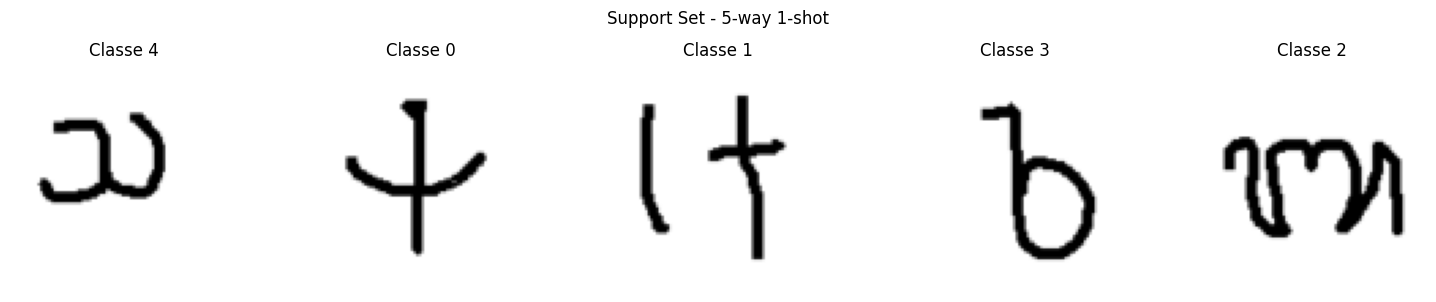

In [29]:
show_images(
    support_images,
    support_labels,
    "Support Set - 5-way 1-shot"
)

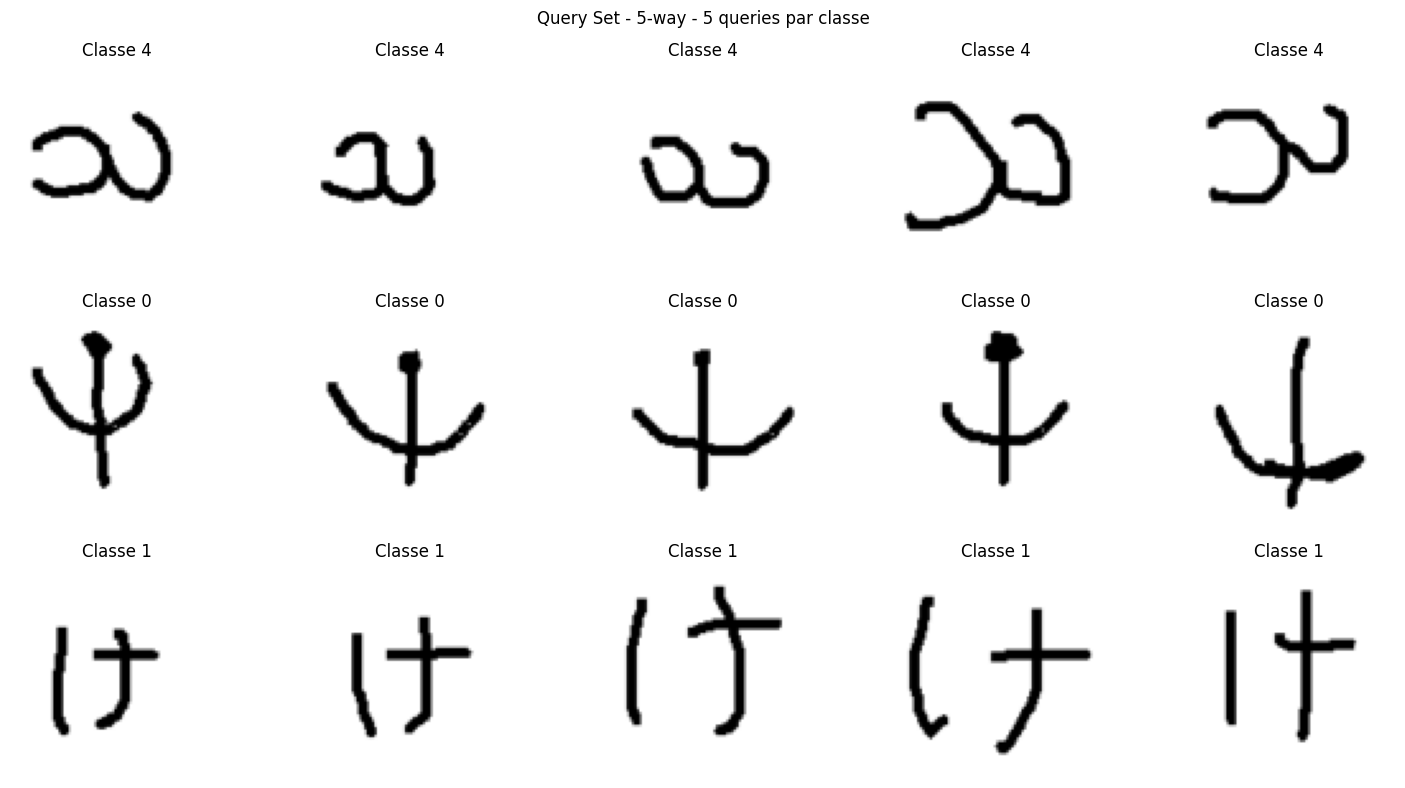

In [30]:
show_images(
    query_images,
    query_labels,
    "Query Set - 5-way - 5 queries par classe"
)

10. Fonction d'embedding avec ResNet18

Pour appliquer les Prototypical Networks, nous avons besoin d'une fonction permettant de transformer chaque image en un vecteur dans un espace de représentation.

Nous utilisons ResNet18 comme réseau d'embedding.

On peut représenter cette fonction par :

$$
f_{\phi}: X \rightarrow \mathbb{R}^{128}
$$

où :

$X$ représente l'espace des images ;
$f_{\phi}$ représente le réseau ResNet18 ;
$\phi$ représente ses paramètres ;
$\mathbb{R}^{128}$ représente l'espace d'embedding de dimension 128.

Ainsi, chaque image est transformée en un vecteur de 128 dimensions.

L'objectif de l'entraînement est d'apprendre un espace dans lequel les images appartenant à une même classe sont proches les unes des autres.

In [31]:
# RESNET18 COMME ENCODEUR
resnet = models.resnet18(weights=None)

in_features = resnet.fc.in_features

resnet.fc = nn.Linear(
    in_features,
    FEATURE_DIMENSION
)

print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

11. Architecture du Prototypical Network

Le Prototypical Network est composé principalement de deux étapes :

une fonction d'embedding ;
un mécanisme de comparaison entre les embeddings et les prototypes.

L'architecture peut être résumée ainsi :

$$
\text{Image}
\rightarrow
\text{ResNet18}
\rightarrow
\text{Embedding}
\rightarrow
\text{Prototype}
\rightarrow
\text{Distance}
\rightarrow
\text{Classification}
$$

Contrairement à une classification classique, le modèle ne possède pas une couche finale avec un nombre fixe de neurones correspondant aux classes.

Les classes sont définies dynamiquement pour chaque épisode à partir du Support Set.

In [32]:
# PROTOTYPICAL NETWORK
class PrototypicalNetwork(nn.Module):

    def __init__(self, encoder):

        super().__init__()

        self.encoder = encoder

    def forward(self, x):

        embeddings = self.encoder(x)

        return embeddings

In [33]:
model = PrototypicalNetwork(
    encoder=resnet
)

model = model.to(device)

print("Modèle envoyé sur :", device)

Modèle envoyé sur : cuda


## 12. Nombre de paramètres

Nous calculons le nombre total de paramètres du modèle ainsi que le
nombre de paramètres entraînables.

Cette mesure est utile pour analyser la complexité du modèle.

Dans le cadre de notre projet, la complexité et le nombre de paramètres
font partie des critères permettant de comparer les différentes méthodes
de Few-Shot Learning.

Un nombre important de paramètres peut notamment avoir un impact sur :

- le temps d'entraînement ;
- la mémoire GPU nécessaire ;
- le coût computationnel.

In [34]:
# NOMBRE DE PARAMÈTRES
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Nombre total de paramètres : "
    f"{total_params:,}"
)

print(
    f"Nombre de paramètres entraînables : "
    f"{trainable_params:,}"
)

Nombre total de paramètres : 11,242,176
Nombre de paramètres entraînables : 11,242,176


13. Calcul des prototypes

Le principe fondamental du Prototypical Network est de représenter chaque classe par un prototype dans l'espace d'embedding.

Soit $S_k$ l'ensemble des exemples du Support Set appartenant à la classe $k$.

Chaque exemple est transformé par l'encodeur :

$$
z_i = f_{\phi}(x_i)
$$

Le prototype de la classe $k$ est ensuite calculé comme la moyenne des embeddings des exemples appartenant à cette classe :

$$
c_k =
\frac{1}{|S_k|}
\sum_{(x_i,y_i)\in S_k}
f_{\phi}(x_i)
$$

où :

$c_k$ est le prototype de la classe $k$ ;
$S_k$ est le Support Set de la classe $k$ ;
$f_{\phi}$ est la fonction d'embedding ;
$f_{\phi}(x_i)$ est l'embedding de l'image $x_i$.

Le prototype peut donc être considéré comme le centre de la classe dans l'espace d'embedding.

In [35]:
# CALCUL DES PROTOTYPES

def compute_prototypes(
    support_embeddings,
    support_labels
):

    classes = torch.unique(
        support_labels,
        sorted=True
    )

    prototypes = []

    prototype_labels = []

    for class_label in classes:

        class_embeddings = support_embeddings[
            support_labels == class_label
        ]

        prototype = class_embeddings.mean(
            dim=0
        )

        prototypes.append(prototype)

        prototype_labels.append(class_label)

    prototypes = torch.stack(
        prototypes
    )

    prototype_labels = torch.stack(
        prototype_labels
    )

    return prototypes, prototype_labels

14. Distance euclidienne

Après avoir calculé les prototypes, nous devons mesurer la distance entre un embedding du Query Set et chaque prototype.

Nous utilisons ici la distance euclidienne au carré :

$$
d(z,c_k)=|z-c_k|_2^2
$$

où :

$z=f_{\phi}(x)$ est l'embedding de l'image query ;
$c_k$ est le prototype de la classe $k$ ;
$d(z,c_k)$ représente la distance entre l'image et le prototype.

Une faible distance signifie que l'image est proche du prototype dans l'espace d'embedding.

In [36]:
# DISTANCE EUCLIDIENNE AU CARRÉ
def squared_euclidean_distance(
    query_embeddings,
    prototypes
):

    distances = torch.cdist(
        query_embeddings,
        prototypes,
        p=2
    ) ** 2

    return distances

15. Fonction de perte Prototypical Network

La fonction de perte utilisée est une Cross-Entropy Loss basée sur les probabilités obtenues à partir des distances.

Pour une image query appartenant réellement à la classe $k$, la perte est :

-\log p_{\phi}(y=k|x)
$$

Le modèle cherche donc à :

réduire la distance entre une image query et le prototype de sa vraie classe ;
augmenter implicitement la différence avec les prototypes des autres classes.

L'apprentissage permet ainsi de construire progressivement un espace d'embedding adapté à la classification Few-Shot.

In [37]:
# PROTOTYPICAL LOSS
def prototypical_loss(
    query_embeddings,
    query_labels,
    prototypes,
    prototype_labels
):

    distances = squared_euclidean_distance(
        query_embeddings,
        prototypes
    )

    # Plus la distance est petite,
    # plus la classe est probable
    logits = -distances

    # Conversion des labels vers les indices
    # des prototypes
    target_indices = torch.zeros(
        len(query_labels),
        dtype=torch.long,
        device=query_labels.device
    )

    for i, label in enumerate(query_labels):

        matching_indices = (
            prototype_labels == label
        ).nonzero(as_tuple=True)[0]

        target_indices[i] = matching_indices[0]

    loss = F.cross_entropy(
        logits,
        target_indices
    )

    # Classe prédite
    predicted_indices = torch.argmax(
        logits,
        dim=1
    )

    predictions = prototype_labels[
        predicted_indices
    ]

    accuracy = (
        predictions == query_labels
    ).float().mean()

    return loss, accuracy

**16. Optimisation du modèle**

Les paramètres du réseau d'embedding sont optimisés à l'aide de l'algorithme Adam.

À chaque épisode :

un Support Set et un Query Set sont générés ;
les images du Support Set sont transformées en embeddings ;
les prototypes sont calculés ;
les images du Query Set sont transformées en embeddings ;
les distances aux prototypes sont calculées ;
la loss est calculée ;
les gradients sont calculés par rétropropagation ;
les paramètres du réseau sont mis à jour.

L'apprentissage est donc effectué épisode par épisode.

In [38]:
# OPTIMIZER
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Optimizer :", optimizer)

Optimizer : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 1e-05
)


**17. Entraînement épisodique**

Le modèle est entraîné pendant 1000 épisodes en configuration :

$$
5\text{-way},\quad 1\text{-shot},\quad 5\text{ queries/classe}
$$

Chaque épisode constitue une nouvelle tâche de classification.

Le modèle ne mémorise donc pas simplement une correspondance entre une image et une classe fixe. Il apprend plutôt à construire un espace d'embedding permettant de comparer efficacement des exemples appartenant à différentes classes.

L'objectif est de développer une capacité de généralisation à de nouvelles tâches Few-Shot.

In [40]:
# ============================================================
# 19. ENTRAÎNEMENT D'UN ÉPISODE
# ============================================================

def train_one_episode(
    model,
    optimizer,
    support_images,
    support_labels,
    query_images,
    query_labels
):

    model.train()

    # Envoyer les données sur le GPU
    support_images = support_images.to(
        device,
        non_blocking=True
    )

    support_labels = support_labels.to(
        device,
        non_blocking=True
    )

    query_images = query_images.to(
        device,
        non_blocking=True
    )

    query_labels = query_labels.to(
        device,
        non_blocking=True
    )

    # --------------------------------------------------------
    # 1. Embeddings du support
    # --------------------------------------------------------

    support_embeddings = model(
        support_images
    )

    # --------------------------------------------------------
    # 2. Embeddings du query
    # --------------------------------------------------------

    query_embeddings = model(
        query_images
    )

    # --------------------------------------------------------
    # 3. Calcul des prototypes
    # --------------------------------------------------------

    prototypes, prototype_labels = compute_prototypes(
        support_embeddings,
        support_labels
    )

    # --------------------------------------------------------
    # 4. Loss + Accuracy
    # --------------------------------------------------------

    loss, accuracy = prototypical_loss(
        query_embeddings,
        query_labels,
        prototypes,
        prototype_labels
    )

    # --------------------------------------------------------
    # 5. Backpropagation
    # --------------------------------------------------------

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    return loss.item(), accuracy.item()

In [41]:
# ============================================================
# 20. TRAINING LOADER
# ============================================================

train_loader, train_sampler = create_episodic_loader(
    train_dataset,
    n_way=5,
    n_shot=1,
    n_query=5,
    n_tasks=1000,
    num_workers=2
)

print("Training loader créé.")

Training loader créé.


In [42]:
# ============================================================
# 21. ENTRAÎNEMENT
# ============================================================

train_losses = []

train_accuracies = []

print("=" * 60)
print("DÉBUT DE L'ENTRAÎNEMENT")
print("=" * 60)

for episode, (
    support_images,
    support_labels,
    query_images,
    query_labels,
    class_ids
) in enumerate(
    train_loader,
    start=1
):

    loss, accuracy = train_one_episode(
        model=model,
        optimizer=optimizer,
        support_images=support_images,
        support_labels=support_labels,
        query_images=query_images,
        query_labels=query_labels
    )

    train_losses.append(loss)

    train_accuracies.append(
        accuracy
    )

    if (
        episode == 1
        or episode % 100 == 0
    ):

        print(
            f"Episode {episode:4d}/1000 "
            f"| Loss : {loss:.4f} "
            f"| Accuracy : "
            f"{accuracy * 100:.2f}%"
        )

print("=" * 60)
print("FIN DE L'ENTRAÎNEMENT")
print("=" * 60)

DÉBUT DE L'ENTRAÎNEMENT
Episode    1/1000 | Loss : 1.6583 | Accuracy : 28.00%
Episode  100/1000 | Loss : 0.4988 | Accuracy : 88.00%
Episode  200/1000 | Loss : 0.3817 | Accuracy : 84.00%
Episode  300/1000 | Loss : 0.6046 | Accuracy : 64.00%
Episode  400/1000 | Loss : 0.5259 | Accuracy : 84.00%
Episode  500/1000 | Loss : 0.0828 | Accuracy : 100.00%
Episode  600/1000 | Loss : 0.2910 | Accuracy : 92.00%
Episode  700/1000 | Loss : 0.2322 | Accuracy : 88.00%
Episode  800/1000 | Loss : 0.4535 | Accuracy : 84.00%
Episode  900/1000 | Loss : 0.0043 | Accuracy : 100.00%
Episode 1000/1000 | Loss : 0.1469 | Accuracy : 92.00%
FIN DE L'ENTRAÎNEMENT


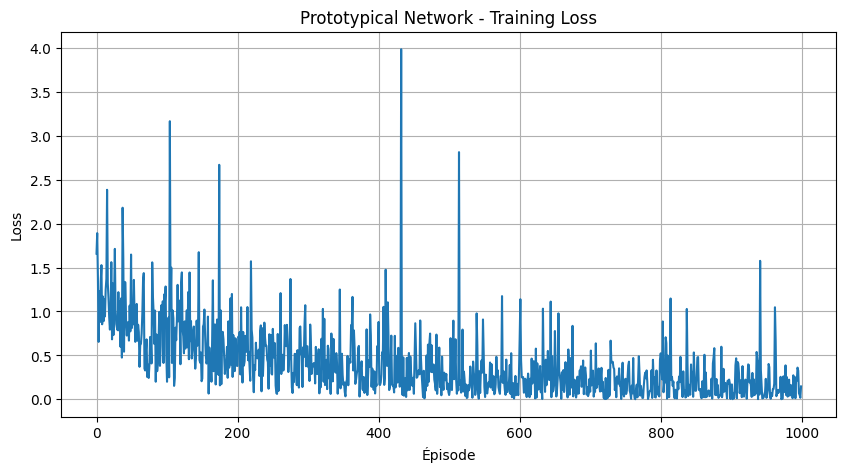

In [43]:
# ============================================================
# 22. COURBE DE LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(train_losses)

plt.xlabel("Épisode")

plt.ylabel("Loss")

plt.title(
    "Prototypical Network - Training Loss"
)

plt.grid(True)

plt.show()

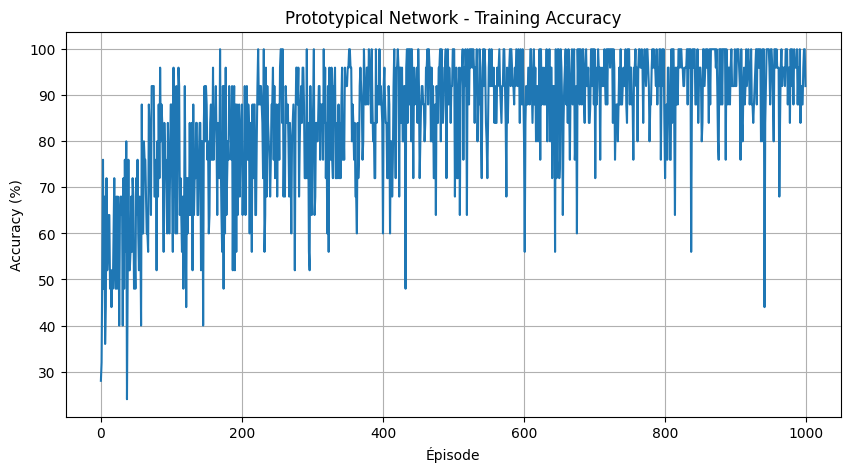

In [44]:
# ============================================================
# 23. COURBE D'ACCURACY
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    np.array(train_accuracies) * 100
)

plt.xlabel("Épisode")

plt.ylabel("Accuracy (%)")

plt.title(
    "Prototypical Network - Training Accuracy"
)

plt.grid(True)

plt.show()

** Analyse des derniers épisodes**

Afin d'obtenir une indication plus stable des performances finales pendant l'entraînement, nous calculons la moyenne de la loss et de l'accuracy sur les 100 derniers épisodes.

Cette moyenne est plus représentative que la valeur obtenue sur un seul épisode, car les épisodes Few-Shot sont générés aléatoirement.

In [45]:
# MOYENNE DES 100 DERNIERS ÉPISODES
last_100_loss = np.mean(
    train_losses[-100:]
)

last_100_accuracy = np.mean(
    train_accuracies[-100:]
)

print(
    f"Loss moyenne des 100 derniers épisodes : "
    f"{last_100_loss:.4f}"
)

print(
    f"Accuracy moyenne des 100 derniers épisodes : "
    f"{last_100_accuracy * 100:.2f}%"
)

Loss moyenne des 100 derniers épisodes : 0.1826
Accuracy moyenne des 100 derniers épisodes : 93.16%


**Évaluation du modèle**

Après l'entraînement, nous évaluons le modèle sur des épisodes qui ne sont pas utilisés pour mettre à jour ses paramètres.

L'objectif est de mesurer sa capacité à généraliser à de nouvelles tâches Few-Shot.

Deux configurations sont étudiées :

5-way 1-shot ;
5-way 5-shot.

Dans les deux cas, nous utilisons :

$$
N=5
$$

et :

$$
Q=5
$$

c'est-à-dire cinq classes et cinq exemples query par classe.

In [46]:
# FONCTION D'ÉVALUATION
def evaluate_prototypical_network(
    model,
    dataset,
    n_way,
    n_shot,
    n_query,
    n_tasks
):

    eval_loader, eval_sampler = create_episodic_loader(
        dataset,
        n_way=n_way,
        n_shot=n_shot,
        n_query=n_query,
        n_tasks=n_tasks,
        num_workers=2
    )

    model.eval()

    episode_accuracies = []

    all_true_labels = []

    all_predictions = []

    with torch.no_grad():

        for (
            support_images,
            support_labels,
            query_images,
            query_labels,
            class_ids
        ) in eval_loader:

            # ------------------------------------------------
            # Envoyer sur GPU
            # ------------------------------------------------

            support_images = support_images.to(
                device,
                non_blocking=True
            )

            support_labels = support_labels.to(
                device,
                non_blocking=True
            )

            query_images = query_images.to(
                device,
                non_blocking=True
            )

            query_labels = query_labels.to(
                device,
                non_blocking=True
            )

            # ------------------------------------------------
            # Embeddings
            # ------------------------------------------------

            support_embeddings = model(
                support_images
            )

            query_embeddings = model(
                query_images
            )

            # ------------------------------------------------
            # Prototypes
            # ------------------------------------------------

            prototypes, prototype_labels = compute_prototypes(
                support_embeddings,
                support_labels
            )

            # ------------------------------------------------
            # Distances
            # ------------------------------------------------

            distances = squared_euclidean_distance(
                query_embeddings,
                prototypes
            )

            # ------------------------------------------------
            # Prédictions
            # ------------------------------------------------

            predicted_indices = torch.argmin(
                distances,
                dim=1
            )

            predictions = prototype_labels[
                predicted_indices
            ]

            # ------------------------------------------------
            # Accuracy de l'épisode
            # ------------------------------------------------

            accuracy = (
                predictions == query_labels
            ).float().mean()

            episode_accuracies.append(
                accuracy.item()
            )

            # ------------------------------------------------
            # Sauvegarder les labels
            # ------------------------------------------------

            all_true_labels.extend(
                query_labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    mean_accuracy = np.mean(
        episode_accuracies
    )

    return (
        mean_accuracy,
        all_true_labels,
        all_predictions,
        episode_accuracies
    )

**Évaluation en 5-way 1-shot**

Dans cette première expérience, chaque classe possède un seul exemple dans le Support Set.

La configuration est :

$$
N=5,\quad K=1,\quad Q=5
$$

Le Support Set contient donc :

$$
5\times1=5
$$

images.

Le Query Set contient :

$$
5\times5=25
$$

images.

Le prototype de chaque classe est directement déterminé par l'unique exemple disponible.

Cette configuration permet d'évaluer la capacité du modèle à réaliser une classification avec une quantité extrêmement limitée d'information.

In [49]:
# 26. ÉVALUATION 5-WAY 1-SHOT
accuracy_1shot, \
y_true_1shot, \
y_pred_1shot, \
episode_acc_1shot = evaluate_prototypical_network(

    model=model,

    dataset=test_dataset,

    n_way=5,

    n_shot=1,

    n_query=5,

    n_tasks=600
)

print(
    f"\nAccuracy 5-way 1-shot : "
    f"{accuracy_1shot * 100:.2f}%"
)


Accuracy 5-way 1-shot : 87.96%


**Évaluation en 5-way 5-shot**

Dans cette deuxième expérience, chaque classe possède cinq exemples dans le Support Set.

La configuration est :

$$
N=5,\quad K=5,\quad Q=5
$$

Le Support Set contient :

$$
5\times5=25
$$

images.

Le Query Set contient toujours :

$$
5\times5=25
$$

images.

Dans cette configuration, chaque prototype est calculé à partir de cinq exemples :

$$
c_k =
\frac{1}{5}
\sum_{i=1}^{5}
f_{\phi}(x_i)
$$

Cette représentation peut être plus robuste car elle utilise plusieurs exemples pour représenter chaque classe.

In [51]:
# ÉVALUATION 5-WAY 5-SHOT
accuracy_5shot, \
y_true_5shot, \
y_pred_5shot, \
episode_acc_5shot = evaluate_prototypical_network(

    model=model,

    dataset=test_dataset,

    n_way=5,

    n_shot=5,

    n_query=5,

    n_tasks=600
)

print(
    f"\nAccuracy 5-way 5-shot : "
    f"{accuracy_5shot * 100:.2f}%"
)


Accuracy 5-way 5-shot : 95.25%


In [52]:
# PRECISION / RECALL / F1
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

In [53]:
precision_1shot = precision_score(
    y_true_1shot,
    y_pred_1shot,
    average="macro",
    zero_division=0
)

recall_1shot = recall_score(
    y_true_1shot,
    y_pred_1shot,
    average="macro",
    zero_division=0
)

f1_1shot = f1_score(
    y_true_1shot,
    y_pred_1shot,
    average="macro",
    zero_division=0
)

In [55]:
# RÉSULTATS FINAUX
print("=" * 70)

print(
    "RÉSULTATS FINAUX - PROTOTYPICAL NETWORK"
)

print("=" * 70)


print("\n5-WAY 1-SHOT")
print("----------------------------")

print(
    f"Accuracy  : "
    f"{accuracy_1shot * 100:.2f}%"
)

print(
    f"Precision : "
    f"{precision_1shot * 100:.2f}%"
)

print(
    f"Recall    : "
    f"{recall_1shot * 100:.2f}%"
)

print(
    f"F1-score  : "
    f"{f1_1shot * 100:.2f}%"
)


print("\n5-WAY 5-SHOT")
print("----------------------------")

print(
    f"Accuracy  : "
    f"{accuracy_5shot * 100:.2f}%"
)

print(
    f"Precision : "
    f"{precision_5shot * 100:.2f}%"
)

print(
    f"Recall    : "
    f"{recall_5shot * 100:.2f}%"
)

print(
    f"F1-score  : "
    f"{f1_5shot * 100:.2f}%"
)

print("=" * 70)

RÉSULTATS FINAUX - PROTOTYPICAL NETWORK

5-WAY 1-SHOT
----------------------------
Accuracy  : 87.96%
Precision : 87.97%
Recall    : 87.96%
F1-score  : 87.96%

5-WAY 5-SHOT
----------------------------
Accuracy  : 95.25%


NameError: name 'precision_5shot' is not defined

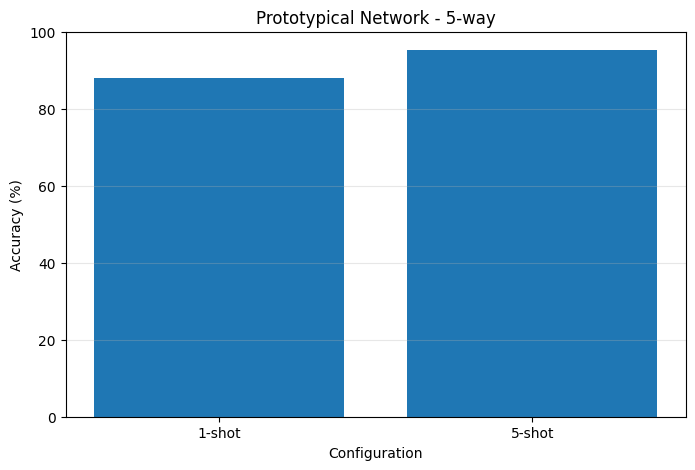

In [56]:
# COMPARAISON 1-SHOT VS 5-SHOT
shots = [
    "1-shot",
    "5-shot"
]

accuracies = [
    accuracy_1shot * 100,
    accuracy_5shot * 100
]

plt.figure(figsize=(8, 5))

plt.bar(
    shots,
    accuracies
)

plt.xlabel("Configuration")

plt.ylabel("Accuracy (%)")

plt.title(
    "Prototypical Network - 5-way"
)

plt.ylim(0, 100)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [57]:
# SAUVEGARDER LE MODÈLE
MODEL_PATH = (
    "prototypical_network_"
    "omniglot_resnet18.pth"
)

torch.save(
    model.state_dict(),
    MODEL_PATH
)

print(
    "Modèle sauvegardé :",
    MODEL_PATH
)

Modèle sauvegardé : prototypical_network_omniglot_resnet18.pth


In [59]:
# RÉSUMÉ DE L'EXPÉRIENCE
print("=" * 70)
print("RÉSUMÉ DU PROJET")
print("=" * 70)

print("Dataset              : Omniglot")
print("Backbone              : ResNet18")
print("Méthode               : Prototypical Network")
print("Nombre de classes     : 5-way")
print("Training              : 1-shot")
print("Queries par classe   : 5")
print("Episodes entraînement : 1000")
print("Episodes évaluation   : 100")
print()
print(
    f"Accuracy 1-shot      : "
    f"{accuracy_1shot * 100:.2f}%"
)
print(
    f"Accuracy 5-shot      : "
    f"{accuracy_5shot * 100:.2f}%"
)

print("=" * 70)

RÉSUMÉ DU PROJET
Dataset              : Omniglot
Backbone              : ResNet18
Méthode               : Prototypical Network
Nombre de classes     : 5-way
Training              : 1-shot
Queries par classe   : 5
Episodes entraînement : 1000
Episodes évaluation   : 100

Accuracy 1-shot      : 87.96%
Accuracy 5-shot      : 95.25%
